# Network Traffic Classification

**Dataset:** `https://archive.ics.uci.edu/dataset/942/rt-iot2022`

**Goal:** Predict the network traffic `Attack_type` using a simple classification model.

## 1. Install libraries

In [1]:
%pip install pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 3. Load the CSV file


In [4]:
file_path = "RT_IOT2022_5000_20pct_messy.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Rows and columns:", df.shape)
df.head()

Dataset loaded successfully
Rows and columns: (5000, 85)


,Record_ID,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,1,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,29729182.958603,29729182.958603,29729182.958603,29729182.958603,0.0,64240,26847,502,MQTT_Publish
1,2,51143,1883,tcp,mqtt,31.88358400000001,9,5,3,3,...,0.0,29855277.061462,29855277.061462,29855277.061462,29855277.061462,0.0,64240,26847,502,MQTT_Publish
2,3,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,29842149.019241,29842149.019241,29842149.019241,29842149.019241,0.0,64240,26847,502,MQTT_Publish
3,4,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,29913774.967194,29913774.967194,29913774.967194,29913774.967194,0.0,64240,26847,502,MQTT_Publish
4,5,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,29814704.89502,29814704.89502,29814704.89502,29814704.89502,0.0,64240,26847,502,MQTT_Publish


## 4. Check the dataset

In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

Column names:
['Record_ID', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_iat.min', 'fwd_iat.max'

,Record_ID,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,1,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,29729182.958603,29729182.958603,29729182.958603,29729182.958603,0.0,64240,26847,502,MQTT_Publish
1,2,51143,1883,tcp,mqtt,31.88358400000001,9,5,3,3,...,0.0,29855277.061462,29855277.061462,29855277.061462,29855277.061462,0.0,64240,26847,502,MQTT_Publish
2,3,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,29842149.019241,29842149.019241,29842149.019241,29842149.019241,0.0,64240,26847,502,MQTT_Publish
3,4,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,29913774.967194,29913774.967194,29913774.967194,29913774.967194,0.0,64240,26847,502,MQTT_Publish
4,5,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,29814704.89502,29814704.89502,29814704.89502,29814704.89502,0.0,64240,26847,502,MQTT_Publish


## 5. Check missing values and duplicate rows

In [6]:
print("Missing values in each column:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:
Record_ID              0
id.orig_p              0
id.resp_p              0
proto                  0
service                0
flow_duration          0
fwd_pkts_tot           0
bwd_pkts_tot           0
fwd_data_pkts_tot      0
bwd_data_pkts_tot      0
fwd_pkts_per_sec       0
bwd_pkts_per_sec       0
flow_pkts_per_sec      0
down_up_ratio          0
fwd_header_size_tot    0
dtype: int64

Duplicate rows: 0


## 6. Remove duplicate rows

In [7]:
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 5000


## 7. Clean messy text values

Some cells contain marks such as `ERR@`, `??`, or `###`. This cell removes the `ERR@` prefix and extra symbols. Values such as `NULL`, `N/A`, `unknown`, and `--` are treated as missing.

We keep the original dataset unchanged by cleaning a copy.

In [9]:

import pandas as pd

# Create a copy so the original dataset remains unchanged
clean_df = df.copy()

# Select text columns explicitly (compatible with newer pandas versions)
text_columns = clean_df.select_dtypes(
    include=["object", "str"]
).columns

# Clean messy text values
for column in text_columns:
    clean_df[column] = (
        clean_df[column]
        .astype("string")
        .str.strip()
        .str.replace("ERR@", "", regex=False)
        .str.replace(r"[^A-Za-z0-9._-]", "", regex=True)
    )

# Mark common missing-value words as missing
missing_words = [
    "", "NULL", "N/A", "NA", "unknown", "--",
    "null", "n/a"
]

# Replace missing-value markers (case-insensitive)
missing_pattern = r"(?i)^(?:NULL|N/A|NA|unknown|--)?$"

for column in text_columns:
    clean_df[column] = clean_df[column].replace(
        missing_words, pd.NA
    )

# Display the cleaned data
print("Example of cleaned data:")
display(clean_df.head())

# Verify the dataset dimensions
print("Dataset shape:", clean_df.shape)


Example of cleaned data:


,Record_ID,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,1,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,29729182.958603,29729182.958603,29729182.958603,29729182.958603,0.0,64240,26847,502,MQTT_Publish
1,2,51143,1883,tcp,mqtt,31.88358400000001,9,5,3,3,...,0.0,29855277.061462,29855277.061462,29855277.061462,29855277.061462,0.0,64240,26847,502,MQTT_Publish
2,3,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,29842149.019241,29842149.019241,29842149.019241,29842149.019241,0.0,64240,26847,502,MQTT_Publish
3,4,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,29913774.967194,29913774.967194,29913774.967194,29913774.967194,0.0,64240,26847,502,MQTT_Publish
4,5,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,29814704.89502,29814704.89502,29814704.89502,29814704.89502,0.0,64240,26847,502,MQTT_Publish


Dataset shape: (5000, 85)


## 8. Select the target and input features
`Attack_type` is the answer we want the model to predict. `Record_ID` is only an ID, so we do not use it as a feature.

In [10]:
target = "Attack_type"

# Remove rows where the target label is missing
clean_df = clean_df.dropna(subset=[target])

X = clean_df.drop(columns=[target, "Record_ID"], errors="ignore")
y = clean_df[target].astype(str)

print("Input rows and columns:", X.shape)
print("\nTarget classes:")
print(y.value_counts())

Input rows and columns: (4993, 83)

Target classes:
Attack_type
MQTT_Publish    4141
Thing_Speak      852
Name: count, dtype: int64


## 9. Convert columns into numeric or category data
Network measurements should be numeric. Text columns such as `proto` and `service` are categories.

In [11]:
# Convert numeric-looking columns to numbers.
# Values that cannot be converted become missing values.
for column in X.columns:
    if column not in ["proto", "service"]:
        X[column] = pd.to_numeric(X[column], errors="coerce")

# Keep proto and service as text categories
for column in ["proto", "service"]:
    if column in X.columns:
        X[column] = X[column].astype("string").fillna("missing")

print("Data types after cleaning:")
print(X.dtypes.value_counts())

Data types after cleaning:
Float64    56
Int64      25
string      2
Name: count, dtype: int64


## 10. Split data into training and testing parts
The model learns from 80% of the data and is tested on the remaining 20%.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 3994
Testing rows: 999


## 11. Prepare the data and train the classification model
The code fills missing numeric values with the median, fills missing categories with the most common value, and converts text categories into numbers.

In [13]:
# Find numeric and text columns
numeric_columns = X_train.select_dtypes(include=["number"]).columns.tolist()
category_columns = X_train.select_dtypes(exclude=["number"]).columns.tolist()

# Prepare numeric columns
numeric_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median"))
])

# Prepare category columns
category_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("convert_text", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preparation to each type of column
prepare_data = ColumnTransformer(transformers=[
    ("numbers", numeric_steps, numeric_columns),
    ("categories", category_steps, category_columns)
])

# Create the classification model
model = Pipeline(steps=[
    ("prepare", prepare_data),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=42))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


## 12. Predict the attack type

In [14]:
predictions = model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted values:")
print(predictions[:10].tolist())

First 10 actual values:
['MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish']

First 10 predicted values:
['MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish', 'MQTT_Publish']


## 13. Check model accuracy and results

In [15]:
accuracy = accuracy_score(y_test, predictions)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))

Accuracy: 99.9 %

Classification report:
              precision    recall  f1-score   support

MQTT_Publish       1.00      1.00      1.00       829
 Thing_Speak       0.99      1.00      1.00       170

    accuracy                           1.00       999
   macro avg       1.00      1.00      1.00       999
weighted avg       1.00      1.00      1.00       999



## 14. Draw a simple graph

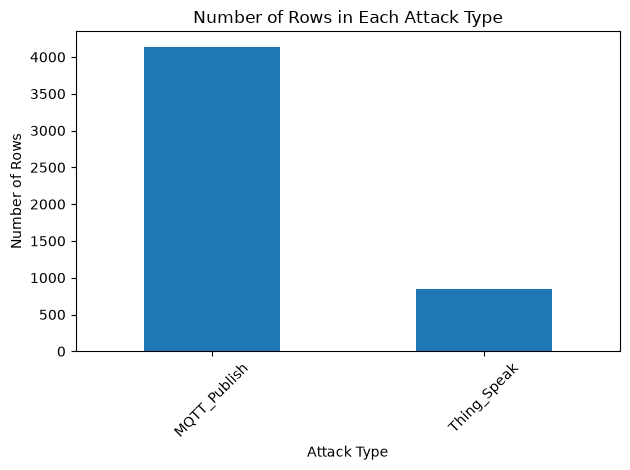

In [16]:
y.value_counts().plot(kind="bar")
plt.title("Number of Rows in Each Attack Type")
plt.xlabel("Attack Type")
plt.ylabel("Number of Rows")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Predicted Traffic Type: MQTT_Publish


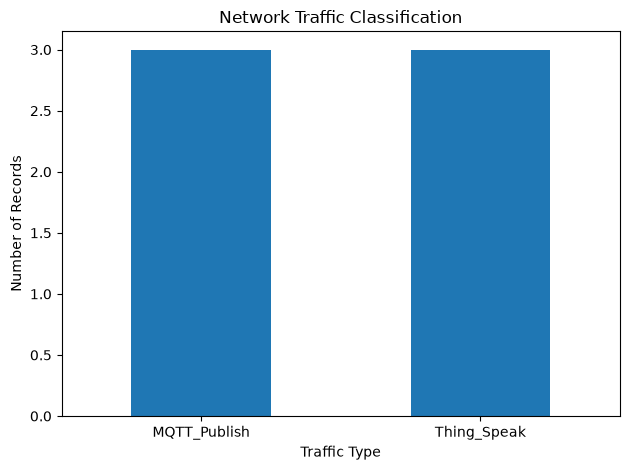

In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# 1. Sample network data
data = {
    "Protocol": ["TCP", "UDP", "TCP", "UDP", "TCP", "UDP"],
    "Traffic_Type": [
        "MQTT_Publish", "Thing_Speak",
        "MQTT_Publish", "Thing_Speak",
        "MQTT_Publish", "Thing_Speak"
    ]
}

df = pd.DataFrame(data)

# 2. Input and target
X = pd.get_dummies(df[["Protocol"]])
y = df["Traffic_Type"]

# 3. Train classification model
model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

# 4. Predict new network traffic
new_data = pd.DataFrame({"Protocol": ["TCP"]})
new_X = pd.get_dummies(new_data).reindex(
    columns=X.columns, fill_value=0
)

prediction = model.predict(new_X)
print("Predicted Traffic Type:", prediction[0])

# 5. Create graph
counts = df["Traffic_Type"].value_counts()

counts.plot(kind="bar")
plt.title("Network Traffic Classification")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 15. Final result
This project cleans the network traffic dataset, trains a Random Forest **classification** model, predicts `Attack_type`, and checks the model using accuracy and a classification report.

**Note:** Accuracy is a test result, not a guarantee that the model will correctly identify every real network attack. The dataset has been cleaned automatically